# 02 · Prediction Setup: what exactly are we predicting?

Notebook 01 decided what *churned* means (provisionally: 60 days without a booking). This notebook
turns that into a **prediction task** with training examples the model can learn from.

### The four design decisions (all set in `src/config.py`)

| Decision | Choice | Why |
|---|---|---|
| **Target** | "Will this customer make *no booking in the next 60 days*?" | A "yes" means they become churned by our definition. 60 days is the horizon; shorten it if the retention team needs a faster signal. |
| **Who is scored** | Customers still *active* (silent < 60 days) | Customers who already churned need win-back, not retention. Including them would also make the task trivially easy. |
| **Training examples** | Monthly *snapshots*: "pretend today is 1 March 2026" | Each snapshot gives one row per active customer, with a known future. Repeating it monthly gives many examples. |
| **Train / test split** | By time, with 60-day buffers | Mimics real use: train on the past, predict the future. |

> ⚠️ **Synthetic data.** The numbers show how the method works, not facts about Snabbit.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd

import churn_definition as cd
import config
import labeling

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

bookings = cd.load_bookings(config.RAW_DIR / "bookings.csv")
dates = labeling.snapshot_dates(bookings)
print(f"{len(dates)} monthly snapshots: {dates[0].date()} → {dates[-1].date()}")
print(f"churn = {config.CHURN_INACTIVITY_DAYS} days silent, horizon = {config.HORIZON_DAYS} days")

18 monthly snapshots: 2025-04-01 → 2026-09-01
churn = 60 days silent, horizon = 60 days


## 1 · Why the split needs gaps

Each snapshot's **label** looks 60 days into the future. If a training snapshot's label window
overlapped the test period, the model would be trained on outcomes from the period we test it
on. That's a subtle form of leakage, and it makes test scores look better than real life.

So each period ends at least 60 days before the next one starts, and snapshots in the gaps are
not used. The chart shows each snapshot's 60-day label window, coloured by split.

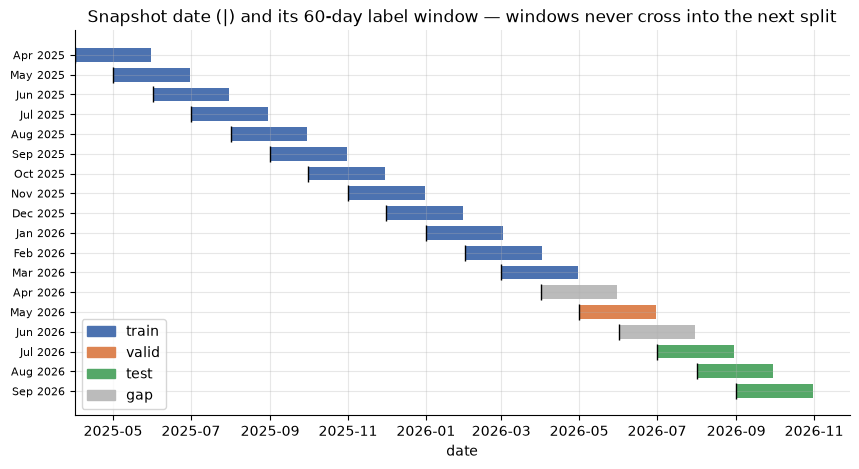

In [2]:
from matplotlib.patches import Patch

colors = {"train": "#4C72B0", "valid": "#DD8452", "test": "#55A868", "gap": "#BBBBBB"}
fig, ax = plt.subplots(figsize=(10, 5))
for i, d in enumerate(dates):
    ax.barh(i, pd.Timedelta(days=config.HORIZON_DAYS), left=d,
            color=colors[labeling.assign_split(d)], height=0.7)
    ax.plot(d, i, "k|", ms=12)
ax.set_yticks(range(len(dates)), [d.strftime("%b %Y") for d in dates], fontsize=8)
ax.invert_yaxis()
ax.legend(handles=[Patch(color=c, label=s) for s, c in colors.items()], loc="lower left")
ax.set(title="Snapshot date (|) and its 60-day label window — windows never cross into the next split",
       xlabel="date")
plt.show()

## 2 · Build labels for all services first

Before excluding anything, we look at every service to see where the labels can be trusted.

In [3]:
labels_all = labeling.build_label_table(bookings, excluded_services=[])
(labels_all.groupby("as_of")
           .agg(split=("split", "first"), customers=("churned", "size"), churn_rate=("churned", "mean")))

,split,customers,churn_rate
as_of,,,
2025-04-01,train,2382,0.179
2025-05-01,train,3077,0.186
2025-06-01,train,3685,0.197
2025-07-01,train,4261,0.206
2025-08-01,train,4787,0.194
2025-09-01,train,5254,0.190
2025-10-01,train,5718,0.197
2025-11-01,train,6156,0.200
2025-12-01,train,6509,0.201


The churn rate is stable at roughly 18–20% per snapshot. The number of active customers grows over
time because the customer base grows. A stable base rate is good news: the model won't have to
cope with a moving target.

## 3 · Can we trust the positive labels?

A positive label says "no booking in the next 60 days". But some of those customers return later.
They had a *temporary lapse*, not real churn. We can measure this **without the answer key**:
for training-period snapshots, we can see months beyond the label window.

In [4]:
last_booking = bookings.groupby("customer_id")["day"].max()
pos = labels_all[(labels_all["churned"] == 1) & (labels_all["split"] == "train")].copy()
window_end = pos["as_of"] + pd.Timedelta(days=config.HORIZON_DAYS)
pos["came_back_later"] = pos["customer_id"].map(last_booking) > window_end

lapse = pos.groupby("main_service")["came_back_later"].agg(lapse_rate="mean", positive_labels="size")
lapse["typical_gap_days"] = cd.service_typical_gaps(bookings, config.TRAIN_END)
lapse.sort_values("lapse_rate")

,lapse_rate,positive_labels,typical_gap_days
main_service,,,
dishwashing,0.024,2291,5.0
cleaning,0.077,4159,9.0
laundry,0.078,1936,9.0
bathroom_cleaning,0.462,1973,26.0
deep_cleaning,0.653,1979,67.0


**This is the key finding of this notebook.** For cleaning, laundry and dishwashing, fewer than
1 in 12 "churned" labels are temporary lapses. For **bathroom cleaning about half are, and for deep
cleaning about two-thirds are.** For a customer who deep-cleans every two months, 60 silent days is
just normal behaviour.

Training on those labels would teach the model noise, and the retention team would chase customers
who weren't leaving. The synthetic answer key confirms it:

In [5]:
truth = pd.read_csv(config.RAW_DIR / "_ground_truth.csv", parse_dates=["true_churn_date"])
pos = pos.merge(truth[["customer_id", "true_churn_date"]], on="customer_id")
pos["truly_gone"] = pos["true_churn_date"] <= pos["as_of"] + pd.Timedelta(days=config.HORIZON_DAYS)
pos.groupby("main_service")["truly_gone"].mean().rename("share truly gone (answer key)").sort_values()

main_service
deep_cleaning        0.291
bathroom_cleaning    0.526
laundry              0.921
cleaning             0.922
dishwashing          0.975
Name: share truly gone (answer key), dtype: float64

### Decision (provisional): version 1 covers frequent services only

`config.EXCLUDED_MAIN_SERVICES` excludes customers whose **main service** is deep cleaning or
bathroom cleaning. They aren't unimportant; they need a different churn definition (a much longer
window), which is a separate piece of work, ideally agreed with the business first.

## 4 · Final label table

In [6]:
print("excluded:", config.EXCLUDED_MAIN_SERVICES)
labels = labeling.build_label_table(bookings)

summary = labels.groupby("split").agg(snapshots=("as_of", "nunique"), rows=("churned", "size"),
                                      customers=("customer_id", "nunique"), churn_rate=("churned", "mean"))
summary.loc[["train", "valid", "test", "gap"]]

excluded: ['deep_cleaning', 'bathroom_cleaning']


,snapshots,rows,customers,churn_rate
split,,,,
train,12,51694,9655,0.162
valid,1,6494,6494,0.165
test,3,21000,8291,0.164
gap,2,13016,7779,0.161


In [7]:
# Safety checks: fail loudly if a future config change breaks these guarantees.
used = labels[labels["split"] != "gap"]
train_label_end = used.loc[used["split"] == "train", "as_of"].max() + pd.Timedelta(days=config.HORIZON_DAYS)
valid_label_end = used.loc[used["split"] == "valid", "as_of"].max() + pd.Timedelta(days=config.HORIZON_DAYS)
assert train_label_end <= used.loc[used["split"] == "valid", "as_of"].min(), "train labels leak into valid"
assert valid_label_end <= used.loc[used["split"] == "test", "as_of"].min(), "valid labels leak into test"
assert (labels["recency_days"] < config.CHURN_INACTIVITY_DAYS).all(), "already-churned customer included"
assert not labels.duplicated(["customer_id", "as_of"]).any(), "duplicate customer in a snapshot"
print("all checks passed")

all checks passed


### How does churn rate relate to current silence?

A quick look at how hard the task is. If recency alone separated churners perfectly, we wouldn't
need a model.

In [8]:
train = labels[labels["split"] == "train"]
(train.groupby(pd.cut(train["recency_days"], [0, 7, 14, 21, 30, 45, 60], right=False), observed=True)["churned"]
      .agg(churn_rate="mean", rows="size"))

,churn_rate,rows
recency_days,,
"[0, 7)",0.041,27328
"[7, 14)",0.095,11180
"[14, 21)",0.223,4657
"[21, 30)",0.409,3158
"[30, 45)",0.637,3085
"[45, 60)",0.832,2286


In [9]:
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
labels.to_csv(config.PROCESSED_DIR / "labels.csv", index=False)
print(f"saved {len(labels):,} rows → data/processed/labels.csv")

saved 92,204 rows → data/processed/labels.csv


## 5 · Conclusions (synthetic data, provisional)

**1. The task.** At each monthly snapshot, take customers who are still active (silent < 60 days) and
predict whether they will make **no booking in the next 60 days**. About **16%** of eligible customers
do, which is consistent across snapshots and splits.

**2. Version 1 covers frequent services only.** For customers whose main service is deep or bathroom
cleaning, roughly half to two-thirds of "churned" labels were temporary lapses; they came back
later. With those excluded, about 92–98% of positive labels are real churn. Bringing infrequent
services back in needs the relative churn rule from notebook 01, so that's version 2.

**3. The split is leak-free by construction.** 12 training snapshots (about 52k rows), 1 validation
snapshot (about 6.5k) and 3 test snapshots (21k), separated by 60-day gaps. Automated checks fail
loudly if a config change ever breaks this.

**4. Recency is powerful but not everything.** Churn rate climbs from 4% (booked within the last
week) to 83% (silent for 45–60 days). That's a strong baseline. The model's job is to separate
customers *within* each recency band, for example two customers both silent for 3 weeks where only
one is drifting away. That's where features like frequency trend, cancellations and ratings should
help.

**5. The same customer appears in many snapshots.** That's fine for a time-based split, but it means
rows aren't independent. We shouldn't use random cross-validation on this table.

### Open questions for Snabbit
- Is a 60-day horizon useful for the retention team, or do they need a 30-day signal?
- Are customers who mainly book deep or bathroom cleaning important enough to prioritise version 2?

**Output:** `data/processed/labels.csv`, the "spine" table (customer_id, as_of, churned, split) that the
feature engineering step will attach features to.
